<a href="https://colab.research.google.com/github/Subhana-sheikh/Linear-Regression-Practice/blob/main/Ridge_and_lasso_reggresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Ridge Regression Algorithm

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV


In [27]:
from sklearn.datasets import fetch_california_housing

In [28]:
data= fetch_california_housing()

In [30]:
df= pd.DataFrame(data.data, columns=data.feature_names)
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [31]:
dataset=df

In [32]:
##Independent features and dependent features
X=dataset.iloc[:,:-1]
y=dataset.iloc[:,-1]

In [33]:
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85
...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43


In [34]:
y

,Longitude
0,-122.23
1,-122.22
2,-122.24
3,-122.25
4,-122.25
...,...
20635,-121.09
20636,-121.21
20637,-121.22
20638,-121.32


In [35]:
X_train,X_test, y_train, y_test= train_test_split(X,y, test_size=0.30, random_state=42)

In [36]:
X_train

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
7061,4.1312,35.0,5.882353,0.975490,1218.0,2.985294,33.93
14689,2.8631,20.0,4.401210,1.076613,999.0,2.014113,32.79
17323,4.2026,24.0,5.617544,0.989474,731.0,2.564912,34.59
10056,3.1094,14.0,5.869565,1.094203,302.0,2.188406,39.26
15750,3.3068,52.0,4.801205,1.066265,1526.0,2.298193,37.77
...,...,...,...,...,...,...,...
11284,6.3700,35.0,6.129032,0.926267,658.0,3.032258,33.78
11964,3.0500,33.0,6.868597,1.269488,1753.0,3.904232,34.02
5390,2.9344,36.0,3.986717,1.079696,1756.0,3.332068,34.03
860,5.7192,15.0,6.395349,1.067979,1777.0,3.178891,37.58


In [37]:
## standardizing the dataset
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [38]:
X_train = scaler.fit_transform(X_train)

In [39]:
X_test= scaler.transform(X_test)

In [40]:
from sklearn.linear_model import LinearRegression

In [41]:
##cross validation
from sklearn.model_selection import cross_val_score

In [42]:
regression=LinearRegression()
regression.fit(X_train, y_train)

LinearRegression()

In [43]:
LinearRegression()

LinearRegression()

In [44]:
ridge_regressor=Ridge()

In [45]:
ridge_regressor

Ridge()

In [46]:
parameters={'alpha':[1,2,5,10,20,30,40,50,60,70,80,90]}
ridgecv=GridSearchCV(ridge_regressor,param_grid=parameters,scoring='neg_mean_squared_error',cv=10)
ridgecv.fit(X_train,y_train)

GridSearchCV(cv=10, estimator=Ridge(),
             param_grid={'alpha': [1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80,
                                   90]},
             scoring='neg_mean_squared_error')

In [47]:
print(ridgecv.best_params_)
print(ridgecv.best_score_)

{'alpha': 60}
-0.4658383952275753


In [48]:
ridge_predict=ridgecv.predict(X_test)

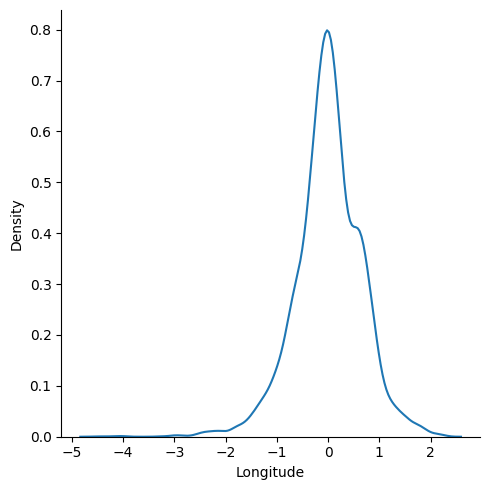

In [49]:
import seaborn as sns
sns.displot(ridge_predict-y_test,kind='kde')

In [52]:
from sklearn.metrics import r2_score

In [53]:
score=r2_score(ridge_predict,y_test)

In [54]:
score

0.8794734486849248

##Lasso Regression

In [55]:
from sklearn.linear_model import Lasso

In [56]:
lasso= Lasso()

In [57]:
parameters={'alpha':[1,2,5,10,20,30,40,50,60,70,80,90]}
lassocv=GridSearchCV(lasso,param_grid=parameters,scoring='neg_mean_squared_error',cv=10)
lassocv.fit(X_train,y_train)

GridSearchCV(cv=10, estimator=Lasso(),
             param_grid={'alpha': [1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80,
                                   90]},
             scoring='neg_mean_squared_error')

In [58]:
print(lassocv.best_params_)
print(lassocv.best_score_)

{'alpha': 1}
-1.5914942182342893


In [59]:
lasso_predict=lassocv.predict(X_test)

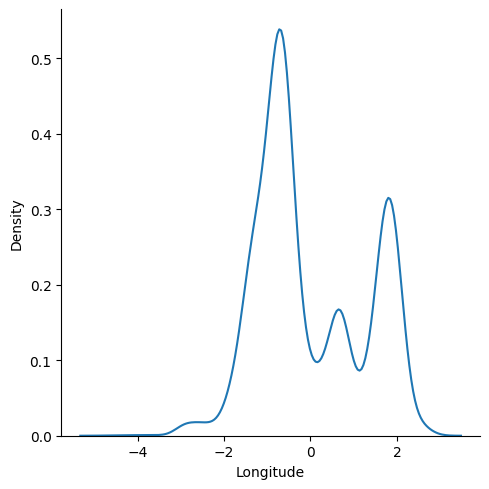

In [60]:
sns.displot(lasso_predict-y_test,kind='kde')